# Moon or minor planet? Fitting an irregular satellite of Jupiter

**The question.** Jupiter has ~100 known moons, most of them small *irregular* satellites
discovered as faint moving dots in survey images. Such a dot is observed and reported to the MPC
exactly like an asteroid. Can an orbit fit tell, from the astrometry alone, that the object is
going around **Jupiter** rather than the Sun, and give its orbit about Jupiter?

We take **Ersa** (S/2018 J 1 = Jupiter LXXI), a ~3 km member of the Himalia group, and contrast it
with **(11351) Leucus**, a Jupiter Trojan (a Lucy-mission target) that shares Jupiter's
*orbit* but never comes near the planet.

PyRoOrb fits every object heliocentrically in a full N-body model (the giant planets are
perturbers, so a satellite's physics is already right). After the fit it asks whether the
object sits inside a giant planet's Hill sphere and, if so, reframes the orbit about that planet.

In [1]:
# Load the PyRoOrb settings file (.env: data folders) before the engine is imported.
from pyroorb.envfile import load_env_file
load_env_file()

import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. Fit both objects: two lines each

In [2]:
obs_moon = pyroorb.fetch_observations("S/2018 J 1")
moon = pyroorb.fit_orbit(obs_moon, designation="S/2018 J 1")

obs_troj = pyroorb.fetch_observations("11351")
trojan = pyroorb.fit_orbit(obs_troj, designation="11351")

for name, f in [("Ersa", moon), ("Leucus", trojan)]:
    yrs = f.arc_length_days() / 365.25
    print(f"{name:7s} {f.n_observations():5d} obs over {yrs:4.1f} yr   rms {f.rms_residual():.2f}\"   "
          f"center: {getattr(f, 'center', None) or 'Sun'}")

(ASSIST) The JPL asteroid ephemeris file has not been found. Asteroid forces have been disabled.


Ersa       67 obs over 25.5 yr   rms 0.22"   center: jupiter
Leucus   3718 obs over 43.9 yr   rms 0.33"   center: Sun


Both fits are excellent (sub-arcsecond residuals), but PyRoOrb has flagged Ersa as orbiting
Jupiter (`fit.center`). Look at what the *heliocentric* elements of the moon say:

In [3]:
for name, f in [("Ersa", moon), ("Leucus", trojan)]:
    el = f.elements()
    print(f"{name:7s} a = {el['a']:.3f} au  e = {el['e']:.3f}  i = {el['i']:5.2f} deg"
          f"  -> heliocentric class: {f.orbit_class()}")

Ersa    a = 7.529 au  e = 0.313  i =  2.62 deg  -> heliocentric class: Centaur
Leucus  a = 5.296 au  e = 0.065  i = 11.55 deg  -> heliocentric class: Jupiter Trojan


Heliocentrically Ersa looks like an odd "Centaur" with a 7.5 au, e = 0.3 orbit: that is
Jupiter's orbit plus the moon's 12-million-km wobble, frozen into a single osculating
Kepler ellipse. The heliocentric class is meaningless for a satellite. The physical
description is the orbit about Jupiter.

## 2. The planet-bound test: distance from Jupiter in Hill radii

The Hill radius, $r_H = a_J (m_J / 3 M_\odot)^{1/3} \approx 0.35$ au, is the region where
Jupiter's gravity beats the Sun's tide. We propagate both fitted orbits for 12 years
(one Jupiter orbit) and measure their distance from Jupiter. Jupiter's position comes from the
same DE440 ephemeris the fit used.
*(This cell uses PyRoOrb's internal propagator, `pyroorb.force_assist`; internal API, may change.)*

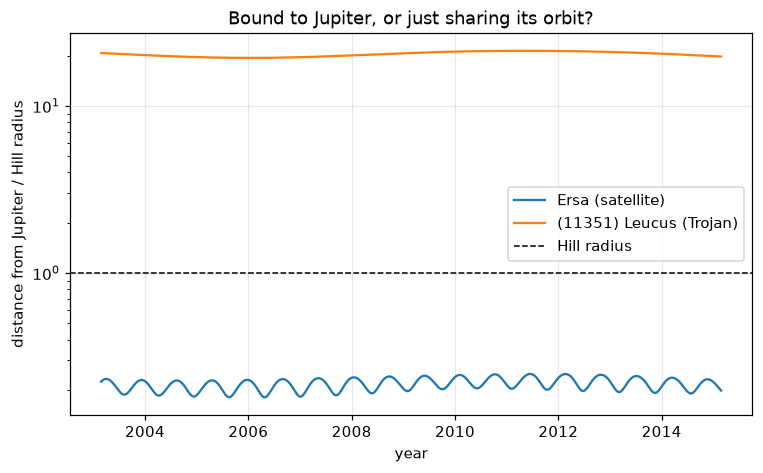

Ersa stays within 0.23 r_H; Leucus never comes closer than 19.4 r_H


In [4]:
import pyroorb.force_assist as fa
from pyroorb.forward_model import PLANETS
from pyroorb.orbital_elements import element_vector, ELEM_NAMES
from pyroorb import planetocentric as pc

eph = fa.get_ephem(False)                       # DE440 planets

def jupiter_state(jd_tdb):
    """Heliocentric equatorial state (au, au/d) of the Jupiter-system barycentre, from DE440."""
    j, s = (eph.get_particle(b, jd_tdb - eph.jd_ref) for b in ("jupiter", "sun"))
    return np.array([j.x - s.x, j.y - s.y, j.z - s.z, j.vx - s.vx, j.vy - s.vy, j.vz - s.vz])

def propagate(f, times_tdb):
    s0 = np.concatenate(f.state_vector())
    return fa.helio_states_multi(f.epoch_tdb, [s0], times_tdb, asteroids=False)[:, 0, :]

t = moon.epoch_tdb + np.linspace(0, 4383, 1500)          # 12 years from the moon's epoch
J = np.array([jupiter_state(x) for x in t])
r_hill = np.linalg.norm(J[:, :3], axis=1) * (PLANETS["jupiter"] / 3) ** (1 / 3)
d_moon = np.linalg.norm(propagate(moon, t)[:, :3] - J[:, :3], axis=1)
d_troj = np.linalg.norm(propagate(trojan, t)[:, :3] - J[:, :3], axis=1)

yr = 2000 + (t - 2451544.5) / 365.25
plt.semilogy(yr, d_moon / r_hill, label="Ersa (satellite)")
plt.semilogy(yr, d_troj / r_hill, label="(11351) Leucus (Trojan)")
plt.axhline(1, color="k", ls="--", lw=1, label="Hill radius")
plt.xlabel("year"); plt.ylabel("distance from Jupiter / Hill radius")
plt.title("Bound to Jupiter, or just sharing its orbit?"); plt.legend()
plt.show()
print(f"Ersa stays within {d_moon.max() / r_hill.max():.2f} r_H; "
      f"Leucus never comes closer than {(d_troj / r_hill).min():.1f} r_H")

Ersa never leaves a quarter of the Hill radius: it is captured. The Trojan shares Jupiter's
~12-year orbit but stays ~5 au away, more than 19 Hill radii, librating about Jupiter's L4
point (60 degrees ahead of the planet).

## 3. The orbit about Jupiter

Reframing the fitted state onto Jupiter and using Jupiter's GM gives jovicentric osculating
elements. PyRoOrb carries the fit's covariance through to them.

In [5]:
def jovicentric(state6, jd_tdb):
    rel = np.asarray(state6)[:6] - jupiter_state(jd_tdb)
    return dict(zip(ELEM_NAMES, element_vector(rel, jd_tdb, mu=pc.planet_gm("jupiter"))))

AU_KM = 1.495978707e8
el = jovicentric(np.concatenate(moon.state_vector()), moon.epoch_tdb)
sig = pc.planetocentric_sigmas(moon, "jupiter")
print(f"Ersa about Jupiter (J2000 ecliptic), epoch JD {moon.epoch_tdb:.2f} TDB")
print(f"  a = {el['a'] * AU_KM / 1e6:.3f} million km  (+/- {sig['a'] * AU_KM:.0f} km)")
print(f"  e = {el['e']:.5f}  (+/- {sig['e']:.5f})")
print(f"  i = {el['i']:.2f} deg -> {'retrograde' if el['i'] > 90 else 'prograde'}")
print(f"  period = {2 * np.pi * np.sqrt(el['a'] ** 3 / pc.planet_gm('jupiter')):.1f} days")

Ersa about Jupiter (J2000 ecliptic), epoch JD 2452694.95 TDB
  a = 11.366 million km  (+/- 9 km)
  e = 0.11452  (+/- 0.00002)
  i = 30.90 deg -> prograde
  period = 247.6 days


## 4. Check against JPL

JPL's satellite ephemeris (`jup347`, integrated with the Galilean moons and Jupiter's
oblateness) gives Ersa's osculating jovicentric elements. We ask Horizons for the same
epoch and frame.

In [6]:
import json, urllib.request, urllib.parse

def horizons(**q):
    q = {"format": "json", **{k: f"'{v}'" for k, v in q.items()}}
    url = "https://ssd.jpl.nasa.gov/api/horizons.api?" + urllib.parse.urlencode(q)
    res = json.load(urllib.request.urlopen(url, timeout=60))["result"]
    return [float(x) for x in res.split("$$SOE")[1].split("$$EOE")[0].split(",")[2:-1]]

# JPL's state of Ersa relative to the Jupiter barycentre, ICRF equatorial (au, au/d)
jpl_state = horizons(COMMAND="571", EPHEM_TYPE="VECTORS", CENTER="500@5", TLIST=moon.epoch_tdb,
                     TIME_TYPE="TDB", VEC_TABLE="2", REF_PLANE="FRAME", OUT_UNITS="AU-D",
                     CSV_FORMAT="YES")[:6]
jpl = dict(zip(ELEM_NAMES, element_vector(np.array(jpl_state), moon.epoch_tdb,
                                          mu=pc.planet_gm("jupiter"))))
ours_rel = np.concatenate(moon.state_vector()) - jupiter_state(moon.epoch_tdb)
print(f"position difference from JPL: {np.linalg.norm(ours_rel[:3] - jpl_state[:3]) * AU_KM:,.0f} km "
      f"(Ersa is {np.linalg.norm(jpl_state[:3]) * AU_KM / 1e6:.1f} million km from Jupiter)\n")
print(f"{'':10s}{'PyRoOrb':>12s}{'JPL':>12s}{'diff':>10s}{'our 1-sigma':>13s}")
for k, scale, unit in [("a", AU_KM / 1e6, "Mkm"), ("e", 1, ""), ("i", 1, "deg"),
                       ("asc_node", 1, "deg"), ("arg_per", 1, "deg"), ("M", 1, "deg")]:
    print(f"{k + ' ' + unit:10s}{el[k] * scale:12.5f}{jpl[k] * scale:12.5f}"
          f"{(el[k] - jpl[k]) * scale:10.5f}{sig[k] * scale:13.5f}")

position difference from JPL: 714 km (Ersa is 12.2 million km from Jupiter)

               PyRoOrb         JPL      diff  our 1-sigma
a Mkm         11.36615    11.36618  -0.00002      0.00001
e              0.11452     0.11453  -0.00001      0.00002
i deg         30.90015    30.90136  -0.00121      0.00114
asc_node deg   111.07518   111.08175  -0.00657      0.00251
arg_per deg   311.07108   311.04531   0.02578      0.00688
M deg        122.92365   122.94906  -0.02542      0.00841


From 67 positions over 25 years, PyRoOrb puts Ersa within ~700 km of JPL's position, on an
orbit 12 million km from Jupiter. The size, shape and tilt of the orbit (a, e, i) agree within
1-2σ. The orientation angles differ by 2.6-3.7σ (a few hundredths of a degree). That is
expected: PyRoOrb treats Jupiter's whole system as one point mass at its
barycentre and does not include the Galilean moons or Jupiter's oblateness. JPL's satellite
integration does. Osculating elements of an irregular moon also swing by percent-level amounts
over a few months under the Sun's tide, so element comparisons have to be at exactly the same
epoch, as here.

**Caveats.** The planet-bound reframing is designed for *irregular* satellites, far out where
the Sun and Jupiter dominate. Inner regular moons need the Galilean moons and J2 as forces,
which PyRoOrb does not model. The helper `planetocentric.planet_helio_state` currently takes
the planet's position from astropy's low-precision built-in ephemeris (~80,000 km off at
Jupiter), so this notebook takes Jupiter from DE440 itself.